<a href="https://colab.research.google.com/github/HANIFAHHASANAH-123140082/mahadata-kelompok3/blob/main/Kelompok3_Mahadata.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Mahadata | Kelompok 3 | Luaran Minggu 9: Eksplorasi dan Pembersihan Data**

**Topik proyek:** Analisis Perubahan Porsi Ulasan Negatif, Tema Keluhan, dan Klasifikasi Ulasan pada Aplikasi Tokopedia 2019–2024

**Sumber data:** Kaggle, *E-Commerce Ratings and Reviews in Bahasa Indonesia* (diambil dari Google Play Store dengan google-play-scraper). Bahtiar, Dewa, & Luthfi (2023), https://doi.org/10.51519/journalisi.v5i3.539


**1. PERSIAPAN LINGKUNGAN**

In [23]:
import os, sys, subprocess
IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    subprocess.run("apt-get install -y -qq openjdk-17-jdk-headless > /dev/null", shell=True, check=True)
    os.environ["JAVA_HOME"] = "/usr/lib/jvm/java-17-openjdk-amd64"
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pyspark==4.2.1"], check=True)

import pyspark
print("Python :", sys.version.split()[0])
print("PySpark:", pyspark.__version__)

Python : 3.13.18
PySpark: 4.2.1


In [24]:
import time
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from pyspark.sql import SparkSession, functions as F
from pyspark import StorageLevel

WORK_DIR = os.environ.get("WORK_DIR", "/content")
os.makedirs(WORK_DIR, exist_ok=True)
os.makedirs(os.path.join(WORK_DIR, "gambar"), exist_ok=True)

spark = (SparkSession.builder
         .master("local[*]")
         .appName("EDA-Tokopedia-Kelompok3")
         .config("spark.driver.memory", os.environ.get("SPARK_MEM", "4g"))
         .config("spark.sql.shuffle.partitions", "16")
         .config("spark.ui.enabled", "false")
         .getOrCreate())
spark.sparkContext.setLogLevel("ERROR")
print("Spark   :", spark.version, "| jumlah core lokal:", spark.sparkContext.defaultParallelism)

Spark   : 4.2.1 | jumlah core lokal: 2


In [25]:
CSV_PATH = os.environ.get("CSV_PATH", "/content/raw_review_googleplay.csv")

if not os.path.exists(CSV_PATH) and IN_COLAB:
    from google.colab import drive
    import zipfile
    drive.mount("/content/drive")
    ZIP_PATH = "/content/drive/MyDrive/TUBES BIGDATA KELOMPOK 3/dataset/archive.zip"   # ubah jika berbeda
    with zipfile.ZipFile(ZIP_PATH) as z:
        z.extract("raw_review_googleplay.csv", "/content")

assert os.path.exists(CSV_PATH), "Berkas CSV tidak ditemukan. Periksa CSV_PATH / ZIP_PATH."
ukuran_mb = os.path.getsize(CSV_PATH) / 1_000_000
print(f"Berkas: {os.path.basename(CSV_PATH)} | ukuran: {ukuran_mb:,.1f} MB")

Berkas: raw_review_googleplay.csv | ukuran: 428.5 MB


In [26]:
t0 = time.time()
raw = (spark.read
       .option("header", True)
       .option("multiLine", True)
       .option("quote", '"')
       .option("escape", '"')
       .csv(CSV_PATH))

PARQUET_DIR = os.path.join(WORK_DIR, "tokopedia_raw.parquet")
raw.write.mode("overwrite").parquet(PARQUET_DIR)
df = spark.read.parquet(PARQUET_DIR)
print(f"Selesai dimuat dan disimpan sebagai Parquet dalam {time.time()-t0:,.0f} detik")

Selesai dimuat dan disimpan sebagai Parquet dalam 21 detik


**2. GAMBARAN DATA**

In [27]:
d = (df
     .withColumn("score_i", F.col("score").cast("int"))
     .withColumn("thumbs_i", F.col("thumbsUpCount").cast("int"))
     .withColumn("at_ts", F.to_timestamp("at"))
     .withColumn("replied_ts", F.to_timestamp("repliedAt")))

n_baris = d.count()
n_kolom = len(df.columns)
rentang = d.agg(F.min("at_ts").alias("awal"), F.max("at_ts").alias("akhir")).collect()[0]

print(f"Jumlah baris : {n_baris:,}")
print(f"Jumlah kolom : {n_kolom}")
print(f"Periode      : {rentang['awal']:%d %B %Y} sampai {rentang['akhir']:%d %B %Y}")
print(f"Ukuran berkas: {ukuran_mb:,.0f} MB (format CSV)")
print("Cakupan wilayah: tidak ada kolom wilayah; data ulasan global dari Google Play")

Jumlah baris : 1,192,500
Jumlah kolom : 11
Periode      : 24 August 2019 sampai 18 September 2024
Ukuran berkas: 428 MB (format CSV)
Cakupan wilayah: tidak ada kolom wilayah; data ulasan global dari Google Play


In [28]:
tipe = pd.DataFrame([
    ["reviewId",             "Pengenal",                 "ID unik ulasan"],
    ["userName",             "Kategorik (anonim)",       "Nama pengguna; hampir semua 'Pengguna Google'"],
    ["userImage",            "Tautan (URL)",             "Foto profil; tidak dipakai"],
    ["content",              "Teks",                     "Isi ulasan; bahan utama model"],
    ["score",                "Numerik ordinal (1-5)",    "Rating; dasar pembuatan label"],
    ["thumbsUpCount",        "Numerik (cacah)",          "Jumlah jempol pada ulasan"],
    ["reviewCreatedVersion", "Kategorik",                "Versi aplikasi saat ulasan dibuat"],
    ["at",                   "Waktu",                    "Waktu ulasan dibuat"],
    ["replyContent",         "Teks",                     "Balasan pihak aplikasi"],
    ["repliedAt",            "Waktu",                    "Waktu balasan"],
    ["appVersion",           "Kategorik",                "Versi aplikasi"],
], columns=["kolom", "tipe", "keterangan"])
display(tipe)

,kolom,tipe,keterangan
0,reviewId,Pengenal,ID unik ulasan
1,userName,Kategorik (anonim),Nama pengguna; hampir semua 'Pengguna Google'
2,userImage,Tautan (URL),Foto profil; tidak dipakai
3,content,Teks,Isi ulasan; bahan utama model
4,score,Numerik ordinal (1-5),Rating; dasar pembuatan label
5,thumbsUpCount,Numerik (cacah),Jumlah jempol pada ulasan
6,reviewCreatedVersion,Kategorik,Versi aplikasi saat ulasan dibuat
7,at,Waktu,Waktu ulasan dibuat
8,replyContent,Teks,Balasan pihak aplikasi
9,repliedAt,Waktu,Waktu balasan


**3. KUALITAS DATA DAN PENANGANANNYA**

In [29]:
# 3a. Data kosong per kolom
agg = [F.sum(F.col(c).isNull().cast("int")).alias(c) for c in df.columns]
miss = d.agg(*agg).toPandas().T.reset_index()
miss.columns = ["kolom", "jumlah_kosong"]
miss["persen"] = (miss["jumlah_kosong"] / n_baris * 100).round(2)
display(miss.sort_values("jumlah_kosong", ascending=False).reset_index(drop=True))

,kolom,jumlah_kosong,persen
0,repliedAt,779658,65.38
1,replyContent,779658,65.38
2,reviewCreatedVersion,390107,32.71
3,appVersion,390107,32.71
4,content,2,0.00
5,reviewId,0,0.00
6,userName,0,0.00
7,userImage,0,0.00
8,score,0,0.00
9,thumbsUpCount,0,0.00


In [30]:
# 3b. Kegagalan format dan nilai di luar rentang
gagal_score  = d.filter(F.col("score").isNotNull() & F.col("score_i").isNull()).count()
gagal_thumbs = d.filter(F.col("thumbsUpCount").isNotNull() & F.col("thumbs_i").isNull()).count()
gagal_waktu  = d.filter(F.col("at").isNotNull() & F.col("at_ts").isNull()).count()
di_luar      = d.filter(~F.col("score_i").between(1, 5)).count()
print("Gagal diubah ke angka (score)      :", gagal_score)
print("Gagal diubah ke angka (thumbsUp)   :", gagal_thumbs)
print("Gagal diubah ke waktu (at)         :", gagal_waktu)
print("Rating di luar 1-5                 :", di_luar)

Gagal diubah ke angka (score)      : 0
Gagal diubah ke angka (thumbsUp)   : 0
Gagal diubah ke waktu (at)         : 0
Rating di luar 1-5                 : 0


In [31]:
# 3c. Duplikasi
n_id_unik = d.select("reviewId").distinct().count()
ada_teks = d.filter(F.col("content").isNotNull())
n_teks_ada = ada_teks.count()
n_teks_unik = ada_teks.select("content").distinct().count()
dup_teks = n_teks_ada - n_teks_unik
print(f"reviewId unik            : {n_id_unik:,} dari {n_baris:,} baris -> duplikat ID: {n_baris-n_id_unik:,}")
print(f"Teks ulasan persis sama  : {dup_teks:,} baris ({dup_teks/n_teks_ada*100:.1f}%) | teks unik: {n_teks_unik:,}")

reviewId unik            : 1,192,500 dari 1,192,500 baris -> duplikat ID: 0
Teks ulasan persis sama  : 508,630 baris (42.7%) | teks unik: 683,868


In [32]:
# 4d. Ulasan sangat pendek / tanpa huruf, dan pencilan
pendek = d.filter(F.col("content").isNotNull() & (F.length(F.trim("content")) <= 3)).count()
tanpa_huruf = d.filter(F.col("content").isNotNull() & ~F.col("content").rlike("[A-Za-z]")).count()
kosong = d.filter(F.col("content").isNull() | (F.trim("content") == "")).count()
print(f"Teks kosong/null               : {kosong:,}")
print(f"Teks <= 3 karakter             : {pendek:,} ({pendek/n_baris*100:.1f}%)")
print(f"Teks tanpa satu pun huruf      : {tanpa_huruf:,} ({tanpa_huruf/n_baris*100:.1f}%)")

pj = d.filter(F.col("content").isNotNull()).select(F.length("content").alias("p")).approxQuantile("p", [0.5, 0.95, 0.99, 1.0], 0.001)
jp = d.filter(F.col("thumbs_i").isNotNull()).select("thumbs_i").approxQuantile("thumbs_i", [0.5, 0.95, 0.99, 1.0], 0.001)
print(f"Panjang teks  : median {pj[0]:.0f}, p95 {pj[1]:.0f}, p99 {pj[2]:.0f}, maksimum {pj[3]:.0f} karakter")
print(f"Jempol (thumbsUpCount): median {jp[0]:.0f}, p95 {jp[1]:.0f}, p99 {jp[2]:.0f}, maksimum {jp[3]:.0f}")

Teks kosong/null               : 2
Teks <= 3 karakter             : 64,306 (5.4%)
Teks tanpa satu pun huruf      : 16,454 (1.4%)
Panjang teks  : median 22, p95 179, p99 352, maksimum 1014 karakter
Jempol (thumbsUpCount): median 0, p95 1, p99 8, maksimum 2795


In [33]:
# 3e. Pemeriksaan privasi (hanya jumlah; isinya tidak ditampilkan)
re_email = r"[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}"
re_hp    = r"(?<![0-9])(\+62|62|0)8[0-9]{8,11}(?![0-9])"
priv = d.agg(
    F.sum((F.col("userName") == "Pengguna Google").cast("int")).alias("anonim"),
    F.sum(F.col("content").rlike(re_email).cast("int")).alias("email"),
    F.sum(F.col("content").rlike(re_hp).cast("int")).alias("telepon"),
).collect()[0]
print(f"userName 'Pengguna Google': {priv['anonim']:,} ({priv['anonim']/n_baris*100:.2f}%)")
print(f"Ulasan memuat pola email    : {priv['email']:,}")
print(f"Ulasan memuat pola telepon  : {priv['telepon']:,}")

userName 'Pengguna Google': 1,190,470 (99.83%)
Ulasan memuat pola email    : 0
Ulasan memuat pola telepon  : 1


### PEMBERSIHAN
Dua versi data dibuat karena tujuannya berbeda:
- **`valid`** (semua ulasan yang sah): dipakai untuk menghitung tren per bulan, karena duplikat teks tetap ulasan yang nyata.
- **`model`** (teks > 3 karakter, ada huruf, tanpa teks ganda): dipakai untuk melatih model, supaya teks yang sama tidak muncul di data latih dan data uji sekaligus.

Label dibuat dari rating: bintang 1–2 = negatif, 4–5 = positif, 3 = netral

In [34]:
STOP = ["yang","dan","di","ke","dari","ini","itu","untuk","dengan","pada","juga","sudah","udah","belum","saya","aku","kami","kita",
        "anda","nya","yg","dg","dgn","sih","deh","aja","saja","lagi","kok","lah","kan","pun","ada","adalah","atau","karena","jadi",
        "bisa","mau","kalau","kalo","jika","agar","supaya","sangat","banget","sekali","lebih","hanya","cuma","sama","para","oleh",
        "dalam","akan","telah","bagi","sebagai","tapi","tetapi","tp","apa","apakah","gimana","bagaimana","tolong","tidak","gak",
        "ga","nggak","enggak","engga","tak","bukan","tokopedia","aplikasi","app","apk","ya","yah","pake","pakai","udh","sdh","dah",
        "dulu","masih","kenapa","mengapa","semua","setiap","bagus","mantap","baik","oke","ok"]

valid = (d
    .drop("userImage", "userName", "score", "thumbsUpCount", "at", "repliedAt")
    .withColumnRenamed("score_i", "score").withColumnRenamed("thumbs_i", "thumbs")
    .withColumnRenamed("at_ts", "at").withColumnRenamed("replied_ts", "replied_at")
    .filter(F.col("content").isNotNull() & (F.trim("content") != "") & F.col("score").isNotNull() & F.col("at").isNotNull())
    .withColumn("content_clean",
        F.regexp_replace(F.regexp_replace(F.regexp_replace(F.lower(F.trim("content")),
            r"https?://\S+", " "), re_email, " "), re_hp, " "))
    .withColumn("content_clean", F.trim(F.regexp_replace("content_clean", r"\s+", " ")))
    .withColumn("tahun", F.year("at"))
    .withColumn("bulan", F.date_format("at", "yyyy-MM"))
    .withColumn("label", F.when(F.col("score") <= 2, "negatif").when(F.col("score") >= 4, "positif").otherwise("netral"))
    .persist(StorageLevel.MEMORY_AND_DISK))

n_valid = valid.count()
kandidat = valid.filter((F.length("content_clean") > 3) & F.col("content_clean").rlike("[a-z]"))
n_kandidat = kandidat.count()
model = kandidat.dropDuplicates(["content_clean"]).persist(StorageLevel.MEMORY_AND_DISK)
n_model = model.count()

ringkas = pd.DataFrame([
    ["Data mentah",                                              n_baris],
    ["Dibuang: teks kosong atau waktu/rating tidak valid",       n_baris - n_valid],
    ["= data 'valid' (untuk tren per bulan)",                    n_valid],
    ["Dibuang: teks <= 3 karakter atau tanpa huruf",             n_valid - n_kandidat],
    ["Dibuang: teks ganda (disisakan satu)",                     n_kandidat - n_model],
    ["= data 'model' (untuk pelatihan model)",                   n_model],
], columns=["tahap", "jumlah_baris"])
ringkas["persen_dari_mentah"] = (ringkas["jumlah_baris"] / n_baris * 100).round(1)
display(ringkas)

dist_model = model.groupBy("label").count().toPandas().set_index("label")
dist_model["persen"] = (dist_model["count"] / n_model * 100).round(1)
print("Sebaran label pada data 'model':")
display(dist_model)

,tahap,jumlah_baris,persen_dari_mentah
0,Data mentah,1192500,100.0
1,Dibuang: teks kosong atau waktu/rating tidak v...,2,0.0
2,= data 'valid' (untuk tren per bulan),1192498,100.0
3,Dibuang: teks <= 3 karakter atau tanpa huruf,69487,5.8
4,Dibuang: teks ganda (disisakan satu),464865,39.0
5,= data 'model' (untuk pelatihan model),658146,55.2


Sebaran label pada data 'model':


,count,persen
label,,
positif,482975,73.4
negatif,146268,22.2
netral,28903,4.4


**VISUALISASI EKSPLORASI**

### Visualisasi 1 = Jumlah ulasan dan porsi ulasan negatif per bulan
Menjawab pertanyaan turunan 1: kapan porsi ulasan negatif berubah, dan apakah jumlah ulasan ikut berubah.

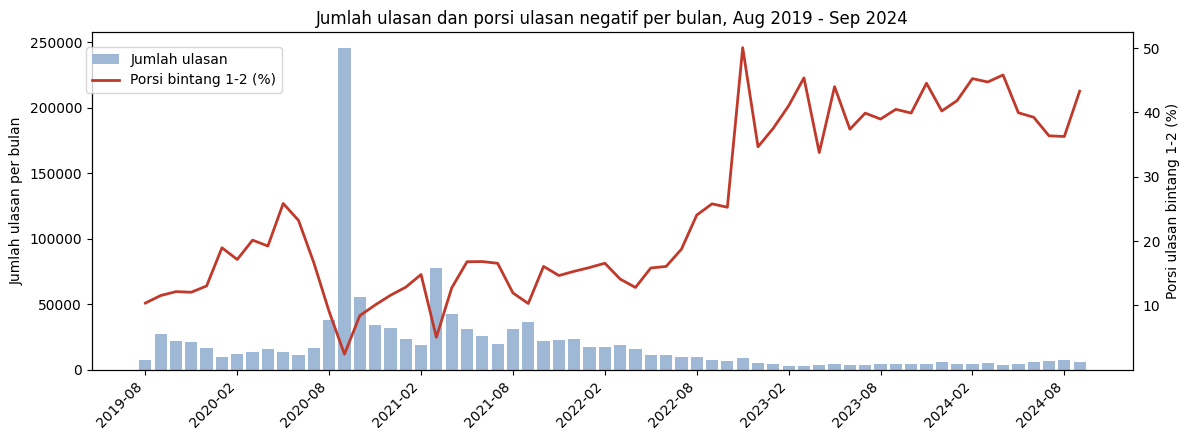

,tahun,jumlah_ulasan,porsi_negatif_pct,perkiraan_jumlah_negatif
0,2019,92788,12.0,11135
1,2020,495939,7.9,39179
2,2021,373490,12.2,45566
3,2022,138313,19.9,27524
4,2023,46357,40.2,18636
5,2024,45611,40.9,18655


Lima bulan dengan jumlah ulasan terbanyak (kemungkinan pencilan volume):


,bulan,jumlah,porsi_negatif_pct
13,2020-09,245444,2.4
19,2021-03,77255,5.0
14,2020-10,55068,8.4
20,2021-04,42574,12.7
12,2020-08,37902,9.0


,bulan,jumlah,porsi_negatif_pct
33,2022-05,11419,15.8
34,2022-06,11380,16.1
35,2022-07,9380,18.7
36,2022-08,9438,24.0
37,2022-09,6988,25.8
38,2022-10,6822,25.3
39,2022-11,8831,50.1
40,2022-12,4828,34.7
41,2023-01,4067,37.5
42,2023-02,2742,41.0


In [35]:
bulanan = (valid.groupBy("bulan")
           .agg(F.count("*").alias("jumlah"), F.avg((F.col("score") <= 2).cast("double")).alias("porsi_negatif"))
           .orderBy("bulan").toPandas())
bulanan["porsi_negatif_pct"] = bulanan["porsi_negatif"] * 100

fig, ax1 = plt.subplots(figsize=(12, 4.5))
ax1.bar(bulanan["bulan"], bulanan["jumlah"], color="#9fb8d6", label="Jumlah ulasan")
ax1.set_ylabel("Jumlah ulasan per bulan")
ax1.set_xticks(range(0, len(bulanan), 6))
ax1.set_xticklabels(bulanan["bulan"][::6], rotation=45, ha="right")
ax2 = ax1.twinx()
ax2.plot(bulanan["bulan"], bulanan["porsi_negatif_pct"], color="#c0392b", linewidth=2, label="Porsi bintang 1-2 (%)")
ax2.set_ylabel("Porsi ulasan bintang 1-2 (%)")
ax1.set_title("Jumlah ulasan dan porsi ulasan negatif per bulan, Aug 2019 - Sep 2024")
fig.legend(loc="upper left", bbox_to_anchor=(0.07, 0.9))
plt.tight_layout()
plt.savefig(os.path.join(WORK_DIR, "gambar", "v1_tren_bulanan.png"), dpi=150)
plt.show()

tahunan = (valid.groupBy("tahun")
           .agg(F.count("*").alias("jumlah_ulasan"), F.round(F.avg((F.col("score") <= 2).cast("double")) * 100, 1).alias("porsi_negatif_pct"))
           .orderBy("tahun").toPandas())
tahunan["perkiraan_jumlah_negatif"] = (tahunan["jumlah_ulasan"] * tahunan["porsi_negatif_pct"] / 100).round(0).astype(int)
display(tahunan)
print("Lima bulan dengan jumlah ulasan terbanyak (kemungkinan pencilan volume):")
display(bulanan.sort_values("jumlah", ascending=False).head(5)[["bulan", "jumlah", "porsi_negatif_pct"]].round(1))
display(bulanan.loc[(bulanan["bulan"] >= "2022-05") & (bulanan["bulan"] <= "2023-03"), ["bulan", "jumlah", "porsi_negatif_pct"]].round(1))

### Visualisasi 2 = Sebaran rating
Menunjukkan apakah kelas tidak seimbang (menentukan pemilihan metrik macro-F1).

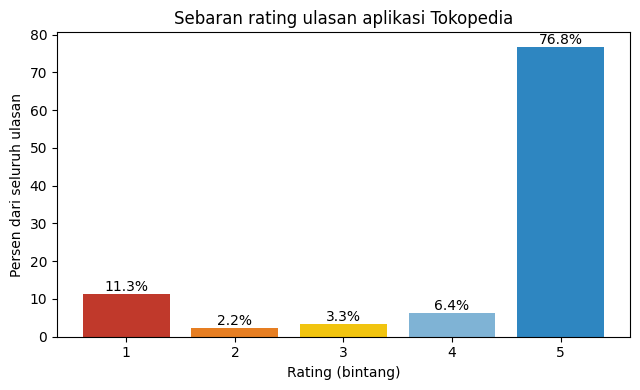

,score,count,persen
0,1,135063,11.3
1,2,26013,2.2
2,3,39347,3.3
3,4,76181,6.4
4,5,915894,76.8


In [36]:
rating = valid.groupBy("score").count().orderBy("score").toPandas()
rating["persen"] = (rating["count"] / n_valid * 100).round(1)

fig, ax = plt.subplots(figsize=(6.5, 4))
bars = ax.bar(rating["score"].astype(str), rating["persen"], color=["#c0392b", "#e67e22", "#f1c40f", "#7fb3d5", "#2e86c1"])
for b, p in zip(bars, rating["persen"]):
    ax.text(b.get_x() + b.get_width() / 2, p + 0.8, f"{p}%", ha="center")
ax.set_xlabel("Rating (bintang)"); ax.set_ylabel("Persen dari seluruh ulasan")
ax.set_title("Sebaran rating ulasan aplikasi Tokopedia")
plt.tight_layout()
plt.savefig(os.path.join(WORK_DIR, "gambar", "v2_sebaran_rating.png"), dpi=150)
plt.show()
display(rating)

### Visualisasi 3 = Kata yang paling sering muncul pada ulasan negatif: sebelum vs sesudah kenaikan
Menjawab pertanyaan turunan 2 secara awal. Yang dihitung: persen ulasan negatif yang memuat kata tersebut. Kata umum dan kata negasi dibuang agar kata bertema lebih terlihat.

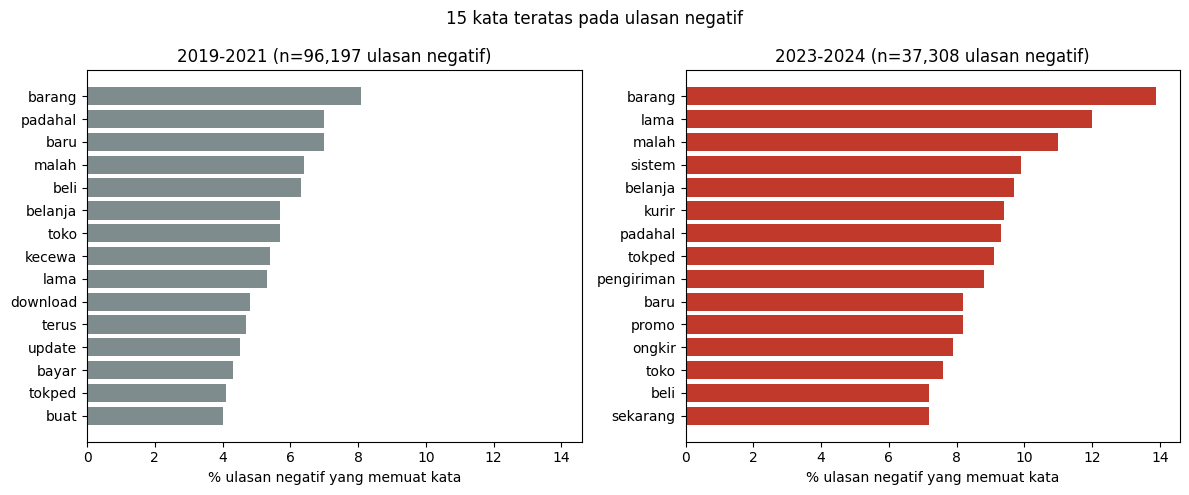

2019-2021: barang (8.1%), padahal (7.0%), baru (7.0%), malah (6.4%), beli (6.3%), belanja (5.7%), toko (5.7%), kecewa (5.4%), lama (5.3%), download (4.8%), terus (4.7%), update (4.5%), bayar (4.3%), tokped (4.1%), buat (4.0%)
2023-2024: barang (13.9%), lama (12.0%), malah (11.0%), sistem (9.9%), belanja (9.7%), kurir (9.4%), padahal (9.3%), tokped (9.1%), pengiriman (8.8%), baru (8.2%), promo (8.2%), ongkir (7.9%), toko (7.6%), beli (7.2%), sekarang (7.2%)


In [37]:
def kata_teratas(frame, n=15):
    total = frame.count()
    kata = (frame.select(F.array_distinct(F.split(F.regexp_replace("content_clean", "[^a-z ]", " "), r"\s+")).alias("w"))
            .select(F.explode("w").alias("kata"))
            .filter((F.length("kata") >= 3) & (~F.col("kata").isin(STOP)))
            .groupBy("kata").count()
            .withColumn("persen", F.round(F.col("count") / total * 100, 1))
            .orderBy(F.desc("count")).limit(n).toPandas())
    return kata, total

neg = valid.filter(F.col("label") == "negatif")
awal,  n_awal  = kata_teratas(neg.filter(F.col("tahun").between(2019, 2021)))
akhir, n_akhir = kata_teratas(neg.filter(F.col("tahun").between(2023, 2024)))

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True)
for ax, tabel, judul in [(axes[0], awal, f"2019-2021 (n={n_awal:,} ulasan negatif)"), (axes[1], akhir, f"2023-2024 (n={n_akhir:,} ulasan negatif)")]:
    t = tabel.iloc[::-1]
    ax.barh(t["kata"], t["persen"], color="#c0392b" if "2023" in judul else "#7f8c8d")
    ax.set_title(judul); ax.set_xlabel("% ulasan negatif yang memuat kata")
plt.suptitle("15 kata teratas pada ulasan negatif")
plt.tight_layout()
plt.savefig(os.path.join(WORK_DIR, "gambar", "v3_kata_negatif.png"), dpi=150)
plt.show()
print("2019-2021:", ", ".join(f"{k} ({p}%)" for k, p in zip(awal["kata"], awal["persen"])))
print("2023-2024:", ", ".join(f"{k} ({p}%)" for k, p in zip(akhir["kata"], akhir["persen"])))

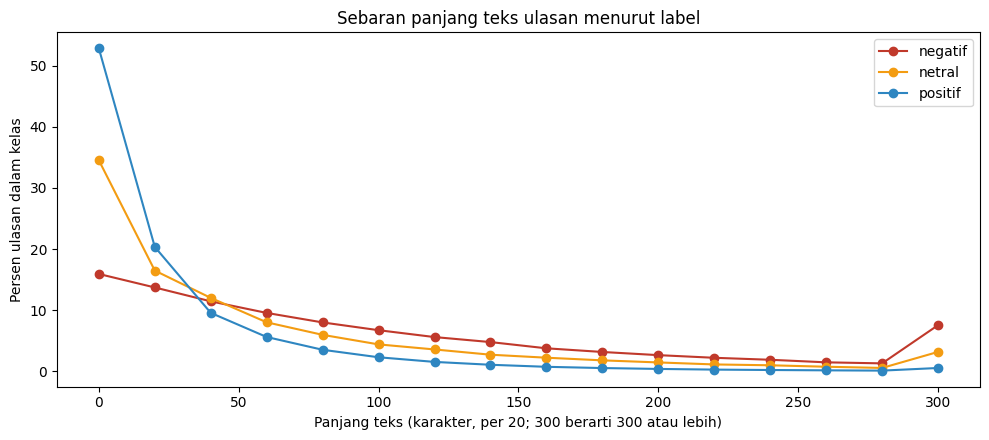

,label,jumlah,median_panjang,rata2_panjang
0,negatif,161076,78,112.8
1,netral,39347,38,69.9
2,positif,992075,17,35.7


In [38]:
panjang = (valid.withColumn("bin", F.least(F.floor(F.length("content_clean") / 20), F.lit(15)) * 20)
           .groupBy("label", "bin").count().toPandas())
total_label = panjang.groupby("label")["count"].transform("sum")
panjang["persen"] = panjang["count"] / total_label * 100

fig, ax = plt.subplots(figsize=(10, 4.5))
for lab, warna in [("negatif", "#c0392b"), ("netral", "#f39c12"), ("positif", "#2e86c1")]:
    p = panjang[panjang["label"] == lab].sort_values("bin")
    ax.plot(p["bin"], p["persen"], marker="o", label=lab, color=warna)
ax.set_xlabel("Panjang teks (karakter, per 20; 300 berarti 300 atau lebih)")
ax.set_ylabel("Persen ulasan dalam kelas")
ax.set_title("Sebaran panjang teks ulasan menurut label")
ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(WORK_DIR, "gambar", "v4_panjang_teks.png"), dpi=150)
plt.show()

stat_panjang = (valid.groupBy("label")
                .agg(F.count("*").alias("jumlah"),
                     F.expr("percentile_approx(length(content_clean), 0.5)").alias("median_panjang"),
                     F.round(F.avg(F.length("content_clean")), 1).alias("rata2_panjang"))
                .orderBy("label").toPandas())
display(stat_panjang)

### Visualisasi 4 = Panjang teks ulasan menurut label
Menunjukkan apakah panjang teks berbeda antar kelas dan berapa banyak ulasan yang sangat pendek.

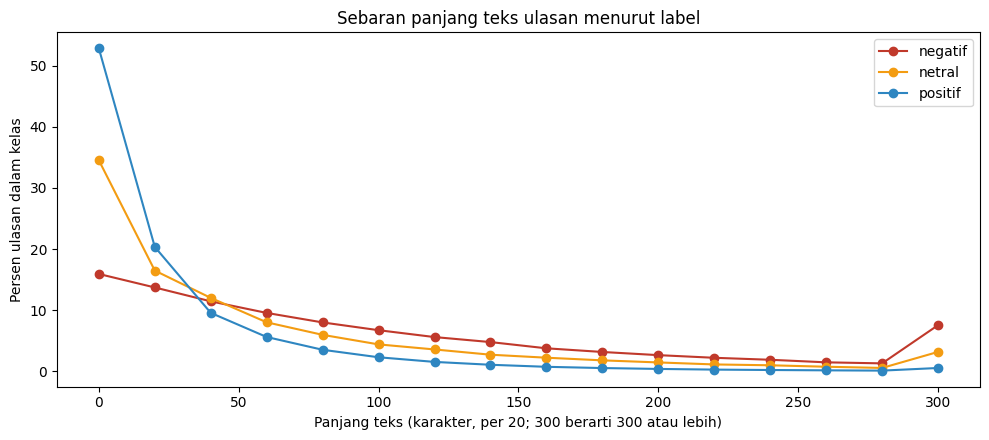

,label,jumlah,median_panjang,rata2_panjang
0,negatif,161076,78,112.8
1,netral,39347,38,69.9
2,positif,992075,17,35.7


In [39]:
panjang = (valid.withColumn("bin", F.least(F.floor(F.length("content_clean") / 20), F.lit(15)) * 20)
           .groupBy("label", "bin").count().toPandas())
total_label = panjang.groupby("label")["count"].transform("sum")
panjang["persen"] = panjang["count"] / total_label * 100

fig, ax = plt.subplots(figsize=(10, 4.5))
for lab, warna in [("negatif", "#c0392b"), ("netral", "#f39c12"), ("positif", "#2e86c1")]:
    p = panjang[panjang["label"] == lab].sort_values("bin")
    ax.plot(p["bin"], p["persen"], marker="o", label=lab, color=warna)
ax.set_xlabel("Panjang teks (karakter, per 20; 300 berarti 300 atau lebih)")
ax.set_ylabel("Persen ulasan dalam kelas")
ax.set_title("Sebaran panjang teks ulasan menurut label")
ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(WORK_DIR, "gambar", "v4_panjang_teks.png"), dpi=150)
plt.show()

stat_panjang = (valid.groupBy("label")
                .agg(F.count("*").alias("jumlah"),
                     F.expr("percentile_approx(length(content_clean), 0.5)").alias("median_panjang"),
                     F.round(F.avg(F.length("content_clean")), 1).alias("rata2_panjang"))
                .orderBy("label").toPandas())
display(stat_panjang)

### Visualisasi 5 = Porsi ulasan negatif menurut versi aplikasi (masa kenaikan, Jun–Des 2022)

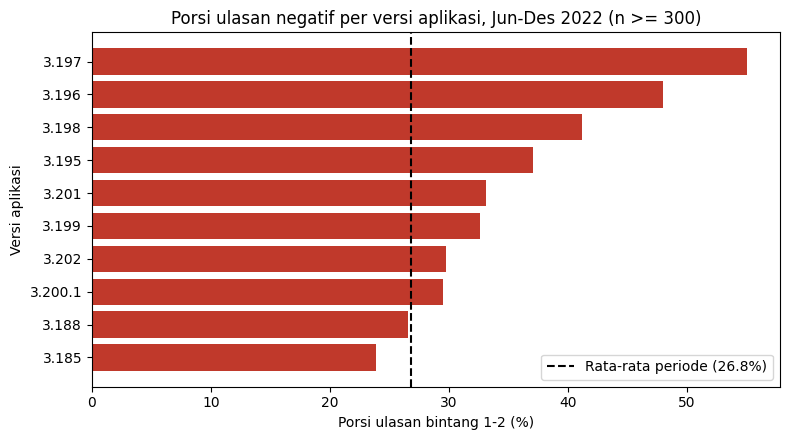

Baris tanpa keterangan versi pada periode ini: 19.0%


,appVersion,jumlah,porsi_negatif_pct
0,3.197,1841,55.1
1,3.196,2177,48.0
2,3.198,869,41.2
3,3.195,1906,37.1
4,3.201,930,33.1
5,3.199,1295,32.6
6,3.202,1205,29.8
7,3.200.1,1470,29.5
8,3.188,2349,26.6
9,3.185,1960,23.9


In [40]:
periode = valid.filter((F.col("at") >= "2022-06-01") & (F.col("at") < "2023-01-01"))
versi_kosong = periode.filter(F.col("appVersion").isNull()).count() / periode.count() * 100
versi = (periode.filter(F.col("appVersion").isNotNull())
         .groupBy("appVersion")
         .agg(F.count("*").alias("jumlah"), F.round(F.avg((F.col("score") <= 2).cast("double")) * 100, 1).alias("porsi_negatif_pct"))
         .filter(F.col("jumlah") >= 300).orderBy(F.desc("porsi_negatif_pct")).limit(10).toPandas())
dasar = periode.agg(F.round(F.avg((F.col("score") <= 2).cast("double")) * 100, 1)).collect()[0][0]

fig, ax = plt.subplots(figsize=(8, 4.5))
t = versi.iloc[::-1]
ax.barh(t["appVersion"], t["porsi_negatif_pct"], color="#c0392b")
ax.axvline(dasar, color="black", linestyle="--", label=f"Rata-rata periode ({dasar}%)")
ax.set_xlabel("Porsi ulasan bintang 1-2 (%)"); ax.set_ylabel("Versi aplikasi")
ax.set_title("Porsi ulasan negatif per versi aplikasi, Jun-Des 2022 (n >= 300)")
ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(WORK_DIR, "gambar", "v5_versi_aplikasi.png"), dpi=150)
plt.show()
print(f"Baris tanpa keterangan versi pada periode ini: {versi_kosong:.1f}%")
display(versi)

## 4. RINGKASAN ANGKA UNTUK CATATAN TEMUAN

In [41]:
print("RINGKASAN")
print(f"- Baris x kolom           : {n_baris:,} x {n_kolom}")
print(f"- Periode                 : {rentang['awal']:%Y-%m-%d} s.d. {rentang['akhir']:%Y-%m-%d}")
print(f"- Teks ganda              : {dup_teks:,} ({dup_teks/n_teks_ada*100:.1f}%)")
print(f"- Teks <= 3 karakter      : {pendek:,}")
print(f"- Data valid / model      : {n_valid:,} / {n_model:,}")
print(f"- Rating 5 / negatif      : {rating.loc[rating.score==5,'persen'].iloc[0]}% / {rating.loc[rating.score<=2,'persen'].sum():.1f}%")
print("- Versi lingkungan        : Python", sys.version.split()[0], "| PySpark", pyspark.__version__, "| Spark", spark.version)

RINGKASAN
- Baris x kolom           : 1,192,500 x 11
- Periode                 : 2019-08-24 s.d. 2024-09-18
- Teks ganda              : 508,630 (42.7%)
- Teks <= 3 karakter      : 64,306
- Data valid / model      : 1,192,498 / 658,146
- Rating 5 / negatif      : 76.8% / 13.5%
- Versi lingkungan        : Python 3.13.18 | PySpark 4.2.1 | Spark 4.2.1
